# Sieci neuronowe i deep learning - Lab 3

## Praktyka trenowania sieci

W tym laboratorium porównujemy wpływ decyzji treningowych na uczenie MLP: learning rate, batch size, optymalizator, inicjalizację, normalizację, dropout i weight decay.

Wersja modelu: **PyTorch**.

## Ćwiczenie 1

- Załaduj zbiór `digits` z `scikit-learn`.
- Podziel dane na zbiory treningowy, walidacyjny i testowy.
- Przeskaluj cechy na podstawie zbioru treningowego.
- Wyświetl kilka przykładowych cyfr.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# TODO: załaduj digits = load_digits()
# Domyslnie uzywamy lekkiego, offline'owego `digits`. Wariant ambitniejszy jest OK,
# jesli po przygotowaniu zostaja macierze X/y do klasyfikacji wieloklasowej.
# TODO: przygotuj X i y
# TODO: wykonaj podział train/validation/test
# TODO: dopasuj StandardScaler tylko na train

digits = load_digits()
X = digits.data.astype("float32")   # (1797, 64): obraz 8x8 spłaszczony do 64 pikseli
y = digits.target.astype("int64")   # cyfry 0-9; CrossEntropyLoss wymaga etykiet int64

# Podział 60/20/20: najpierw 20% na test, potem 25% z pozostałych 80% na walidację.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("train:", X_train.shape)
print("validation:", X_val.shape)
print("test:", X_test.shape)

train: (1077, 64)
validation: (360, 64)
test: (360, 64)


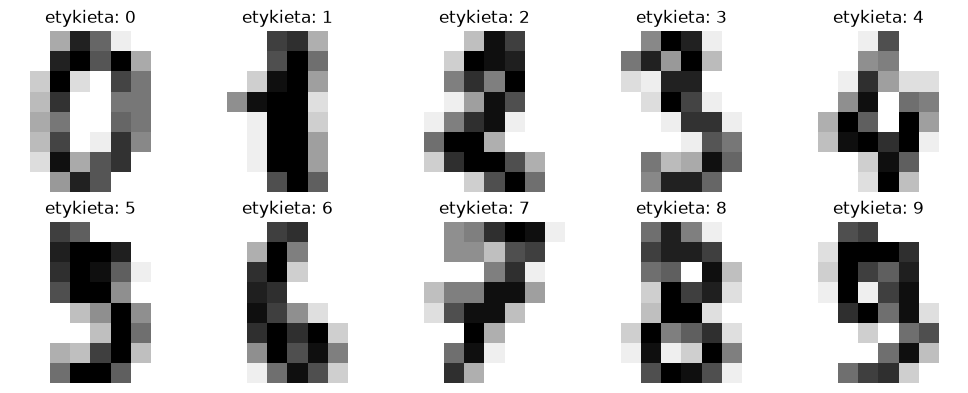

In [3]:
# TODO: wyświetl kilka obrazów z digits.images razem z etykietami.

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"etykieta: {digits.target[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Ćwiczenie 2

- Przygotuj funkcje pomocnicze do rysowania krzywych uczenia i porównywania eksperymentów.
- W tabeli zapisuj końcową stratę oraz accuracy dla zbioru treningowego i walidacyjnego.

To jest prosty dziennik eksperymentów. Bez niego łatwo pomylić, która konfiguracja faktycznie działała lepiej.

In [4]:
def plot_curves(history, title):
    # TODO: narysuj loss/val_loss oraz accuracy/val_accuracy
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title} - loss")
    axes[0].set_xlabel("epoka")
    axes[0].legend()

    axes[1].plot(history["accuracy"], label="train")
    axes[1].plot(history["val_accuracy"], label="validation")
    axes[1].set_title(f"{title} - accuracy")
    axes[1].set_xlabel("epoka")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def plot_comparison(histories, metric, title):
    # Jedna krzywa na eksperyment, żeby porównać kilka konfiguracji na jednym wykresie.
    for name, history in histories.items():
        plt.plot(history[metric], label=name)
    plt.title(title)
    plt.xlabel("epoka")
    plt.ylabel(metric)
    plt.legend()
    plt.show()


def summarize_history(name, history):
    # TODO: zwróć słownik z końcowymi wartościami train/validation loss oraz accuracy
    return {
        "name": name,
        "train_loss": history["loss"][-1],
        "val_loss": history["val_loss"][-1],
        "train_acc": history["accuracy"][-1],
        "val_acc": history["val_accuracy"][-1],
    }


def print_experiment_table(results):
    # TODO: wypisz porównanie eksperymentów w czytelnej tabeli
    header = f"{'eksperyment':<28} {'train_loss':>10} {'val_loss':>9} {'train_acc':>9} {'val_acc':>8}"
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{r['name']:<28} {r['train_loss']:>10.4f} {r['val_loss']:>9.4f} "
            f"{r['train_acc']:>9.3f} {r['val_acc']:>8.3f}"
        )

## Ćwiczenie 3

- Przygotuj klasę MLP oraz funkcję trenującą pojedynczy eksperyment.
- Parametrami eksperymentu powinny być m.in. learning rate, batch size, optymalizator, dropout, batch normalization, weight decay i inicjalizacja.

In [5]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(RANDOM_STATE)

N_CLASSES = len(np.unique(y))  # 10 cyfr
N_HIDDEN_LAYERS = 2            # liczba warstw ukrytych MLP
EVAL_BATCH_SIZE = 256          # batch przy ocenie; w trybie eval nie wpływa na wynik, tylko na szybkość
EXP_LR_GAMMA = 0.9             # ExponentialLR: lr mnożony przez 0.9 co epokę (po 25 epokach ~7% startowego)


def make_torch_loader(X_array, y_array, batch_size, shuffle=False):
    # TODO: utwórz DataLoader z TensorDataset
    X_tensor = torch.tensor(X_array, dtype=torch.float32)
    y_tensor = torch.tensor(y_array, dtype=torch.long)  # indeksy klas, kształt (N,)
    return DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=batch_size, shuffle=shuffle)


class TorchMLP(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_units=64,
        dropout_rate=0.0,
        use_batchnorm=False,
        init_name="xavier",
    ):
        super().__init__()
        # TODO: zbuduj MLP z opcjonalnym BatchNorm1d i Dropout
        layers = []
        in_features = input_dim
        for _ in range(N_HIDDEN_LAYERS):
            layers.append(nn.Linear(in_features, hidden_units))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(hidden_units))
            layers.append(nn.ReLU())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            in_features = hidden_units
        layers.append(nn.Linear(in_features, N_CLASSES))  # logity, bez softmaxu
        self.net = nn.Sequential(*layers)

        for module in self.modules():
            if isinstance(module, nn.Linear):
                if init_name == "xavier":
                    nn.init.xavier_uniform_(module.weight)
                elif init_name == "he":
                    nn.init.kaiming_uniform_(module.weight, nonlinearity="relu")
                else:
                    raise ValueError(f"Nieznana inicjalizacja: {init_name}")
                nn.init.zeros_(module.bias)

    def forward(self, x):
        # TODO: forward pass
        return self.net(x)


def run_epoch(model, loader, loss_fn, optimizer=None):
    # TODO: jedna epoka treningu albo ewaluacji
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:
        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)

        if is_train:
            loss.backward()
            optimizer.step()

        batch_size = X_batch.shape[0]
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == y_batch).sum().item()
        total += batch_size

    return total_loss / total, correct / total


def train_torch_experiment(
    name,
    learning_rate=0.001,
    batch_size=32,
    optimizer_name="adam",
    epochs=25,
    dropout_rate=0.0,
    use_batchnorm=False,
    weight_decay=0.0,
    init_name="xavier",
    scheduler_name=None,
):
    # TODO: zbuduj model, wybierz optymalizator, wykonaj pętlę epok i zwróć model/history/summary

    # To samo ziarno w każdym eksperymencie: te same wagi startowe i ta sama kolejność batchy.
    torch.manual_seed(RANDOM_STATE)

    train_loader = make_torch_loader(X_train, y_train, batch_size, shuffle=True)
    train_eval_loader = make_torch_loader(X_train, y_train, EVAL_BATCH_SIZE)
    val_loader = make_torch_loader(X_val, y_val, EVAL_BATCH_SIZE)

    model = TorchMLP(
        input_dim=X_train.shape[1],
        dropout_rate=dropout_rate,
        use_batchnorm=use_batchnorm,
        init_name=init_name,
    )
    loss_fn = nn.CrossEntropyLoss()

    if optimizer_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    else:
        raise ValueError(f"Nieznany optymalizator: {optimizer_name}")

    if scheduler_name is None:
        scheduler = None
    elif scheduler_name == "exponential":
        scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=EXP_LR_GAMMA)
    else:
        raise ValueError(f"Nieznany scheduler: {scheduler_name}")

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": [], "lr": []}
    for epoch in range(epochs):
        history["lr"].append(optimizer.param_groups[0]["lr"])

        run_epoch(model, train_loader, loss_fn, optimizer)
        # Train oceniany po epoce w trybie eval, tak samo jak walidacja (bez dropoutu,
        # BatchNorm na statystykach kroczących), żeby różnica train - val była porównywalna.
        train_loss, train_acc = run_epoch(model, train_eval_loader, loss_fn)
        val_loss, val_acc = run_epoch(model, val_loader, loss_fn)

        history["loss"].append(train_loss)
        history["accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if scheduler is not None:
            scheduler.step()

    summary = summarize_history(name, history)
    print(f"{name}: train_acc={summary['train_acc']:.3f}  val_acc={summary['val_acc']:.3f}")
    return model, history, summary

## Ćwiczenie 4

- Uruchom baseline: Adam, learning rate `0.001`, batch size `32`.
- Narysuj krzywe uczenia i zapisz wynik w tabeli eksperymentów.

baseline adam lr=0.001: train_acc=1.000  val_acc=0.964


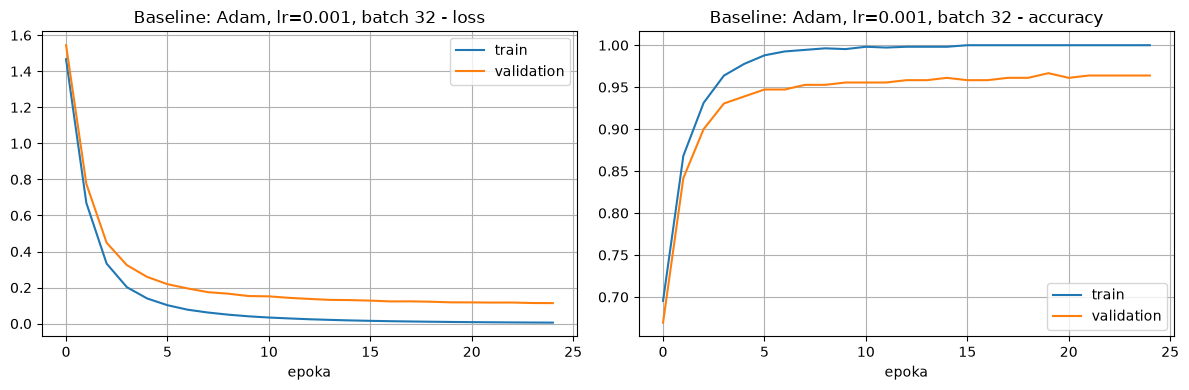

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964


In [6]:
torch_results = []
trained_models = {}
histories = {}


def record(model, history, summary):
    torch_results.append(summary)
    trained_models[summary["name"]] = model
    histories[summary["name"]] = history


# TODO: uruchom baseline Adam lr=0.001, batch_size=32.
# TODO: narysuj krzywe i dodaj wynik do torch_results.
record(*train_torch_experiment("baseline adam lr=0.001"))
plot_curves(histories["baseline adam lr=0.001"], "Baseline: Adam, lr=0.001, batch 32")
print_experiment_table(torch_results)

## Ćwiczenie 5

- Porównaj kilka wartości learning rate.
- Zwróć uwagę na sytuacje, w których model uczy się bardzo wolno albo niestabilnie.

adam lr=0.0001: train_acc=0.927  val_acc=0.886


adam lr=0.05: train_acc=0.769  val_acc=0.725


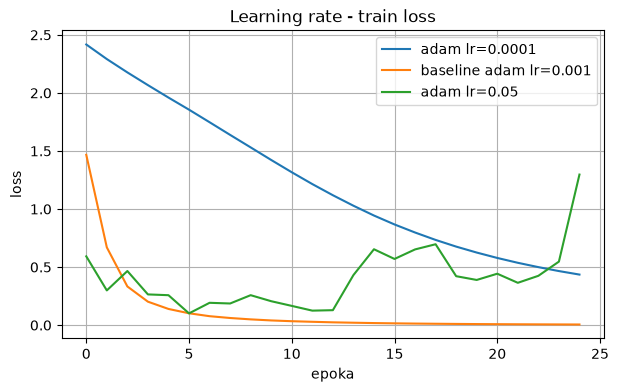

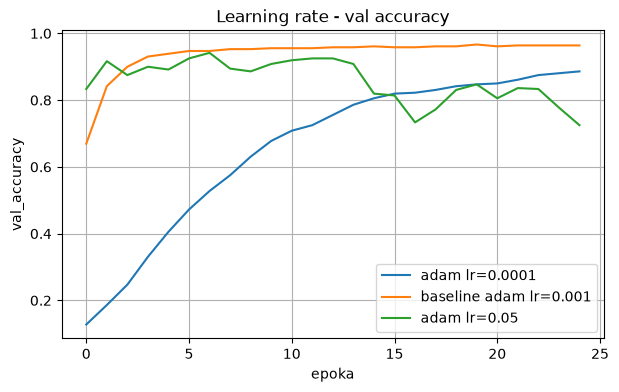

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964
adam lr=0.0001                   0.4355    0.5525     0.927    0.886
adam lr=0.05                     1.2968    1.7392     0.769    0.725


In [7]:
# TODO: uruchom eksperymenty dla kilku learning rate, np. 0.0001, 0.001, 0.05.
# TODO: porównaj wyniki w tabeli.

for lr in [0.0001, 0.05]:
    record(*train_torch_experiment(f"adam lr={lr}", learning_rate=lr))

lr_names = ["adam lr=0.0001", "baseline adam lr=0.001", "adam lr=0.05"]
plot_comparison({n: histories[n] for n in lr_names}, "loss", "Learning rate - train loss")
plot_comparison({n: histories[n] for n in lr_names}, "val_accuracy", "Learning rate - val accuracy")
print_experiment_table([r for r in torch_results if r["name"] in lr_names])

## Ćwiczenie 6

- Porównaj batch size oraz optymalizatory SGD i Adam.
- Sprawdź, czy ta sama wartość learning rate działa podobnie dla obu optymalizatorów.

sgd lr=0.001: train_acc=0.465  val_acc=0.472


sgd lr=0.05: train_acc=0.997  val_acc=0.958


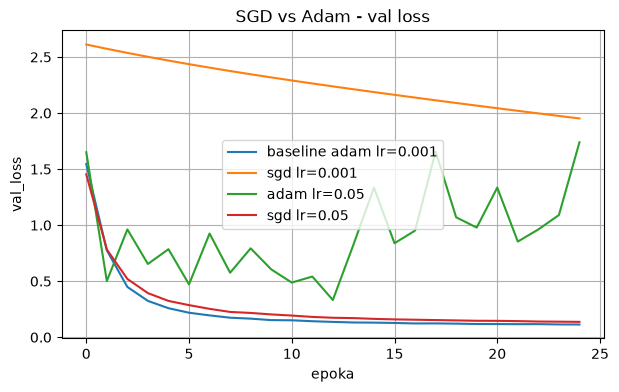

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964
adam lr=0.05                     1.2968    1.7392     0.769    0.725
sgd lr=0.001                     1.8767    1.9518     0.465    0.472
sgd lr=0.05                      0.0218    0.1373     0.997    0.958


adam lr=0.001 bs=16: train_acc=1.000  val_acc=0.972


adam lr=0.001 bs=128: train_acc=0.996  val_acc=0.956


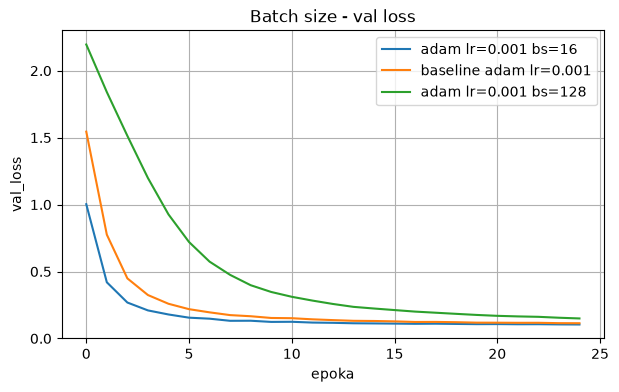

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964
adam lr=0.001 bs=16              0.0021    0.1043     1.000    0.972
adam lr=0.001 bs=128             0.0407    0.1495     0.996    0.956


In [8]:
# TODO: porównaj SGD i Adam oraz batch_size 16 i 128.

for lr in [0.001, 0.05]:
    record(*train_torch_experiment(f"sgd lr={lr}", learning_rate=lr, optimizer_name="sgd"))

opt_names = ["baseline adam lr=0.001", "sgd lr=0.001", "adam lr=0.05", "sgd lr=0.05"]
plot_comparison({n: histories[n] for n in opt_names}, "val_loss", "SGD vs Adam - val loss")
print_experiment_table([r for r in torch_results if r["name"] in opt_names])

for bs in [16, 128]:
    record(*train_torch_experiment(f"adam lr=0.001 bs={bs}", batch_size=bs))

bs_names = ["adam lr=0.001 bs=16", "baseline adam lr=0.001", "adam lr=0.001 bs=128"]
plot_comparison({n: histories[n] for n in bs_names}, "val_loss", "Batch size - val loss")
print_experiment_table([r for r in torch_results if r["name"] in bs_names])

## Ćwiczenie 7

- Dodaj dropout, weight decay oraz batch normalization.
- Porównaj różnicę między accuracy treningowym i walidacyjnym.

dropout 0.3: train_acc=0.997  val_acc=0.964


weight decay 1e-3: train_acc=1.000  val_acc=0.967


batchnorm: train_acc=1.000  val_acc=0.958


dropout + wd + batchnorm: train_acc=0.996  val_acc=0.964


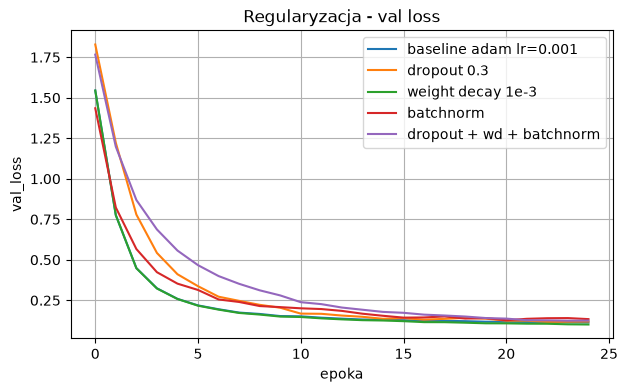

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964
dropout 0.3                      0.0243    0.1194     0.997    0.964
weight decay 1e-3                0.0094    0.1010     1.000    0.967
batchnorm                        0.0093    0.1342     1.000    0.958
dropout + wd + batchnorm         0.0461    0.1251     0.996    0.964

baseline adam lr=0.001       train_acc - val_acc = 0.036
dropout 0.3                  train_acc - val_acc = 0.033
weight decay 1e-3            train_acc - val_acc = 0.033
batchnorm                    train_acc - val_acc = 0.042
dropout + wd + batchnorm     train_acc - val_acc = 0.032


In [9]:
# TODO: uruchom eksperyment z dropout, weight decay i batch normalization.
# TODO: porównaj train/validation accuracy.

reg_configs = {
    "dropout 0.3": dict(dropout_rate=0.3),
    "weight decay 1e-3": dict(weight_decay=1e-3),
    "batchnorm": dict(use_batchnorm=True),
    "dropout + wd + batchnorm": dict(dropout_rate=0.3, weight_decay=1e-3, use_batchnorm=True),
}
for name, config in reg_configs.items():
    record(*train_torch_experiment(name, **config))

reg_names = ["baseline adam lr=0.001"] + list(reg_configs)
plot_comparison({n: histories[n] for n in reg_names}, "val_loss", "Regularyzacja - val loss")
print_experiment_table([r for r in torch_results if r["name"] in reg_names])

print()
for r in torch_results:
    if r["name"] in reg_names:
        gap = r["train_acc"] - r["val_acc"]
        print(f"{r['name']:<28} train_acc - val_acc = {gap:.3f}")

## Ćwiczenie 8

- Dodaj scheduler learning rate.
- Porównaj wynik z eksperymentami bez schedulera.

adam lr=0.05 + exponential: train_acc=0.996  val_acc=0.967


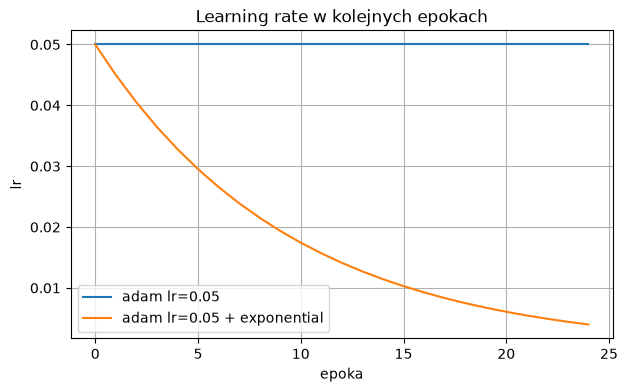

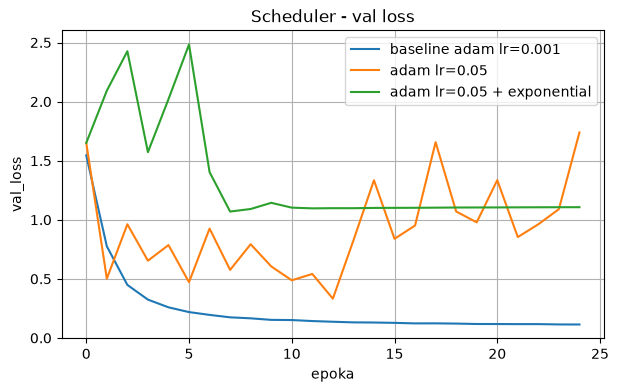

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964
adam lr=0.05                     1.2968    1.7392     0.769    0.725
adam lr=0.05 + exponential       0.0098    1.1065     0.996    0.967


In [10]:
# TODO: dodaj scheduler learning rate, np. ExponentialLR.
# TODO: porównaj wynik z wcześniejszymi eksperymentami.

record(*train_torch_experiment("adam lr=0.05 + exponential", learning_rate=0.05, scheduler_name="exponential"))

sched_names = ["baseline adam lr=0.001", "adam lr=0.05", "adam lr=0.05 + exponential"]
plt.plot(histories["adam lr=0.05"]["lr"], label="adam lr=0.05")
plt.plot(histories["adam lr=0.05 + exponential"]["lr"], label="adam lr=0.05 + exponential")
plt.title("Learning rate w kolejnych epokach")
plt.xlabel("epoka")
plt.ylabel("lr")
plt.legend()
plt.show()

plot_comparison({n: histories[n] for n in sched_names}, "val_loss", "Scheduler - val loss")
print_experiment_table([r for r in torch_results if r["name"] in sched_names])

## Ćwiczenie 9

- Wybierz najlepszy model na podstawie walidacji.
- Dopiero teraz oblicz wynik na zbiorze testowym i wyświetl macierz pomyłek.

eksperyment                  train_loss  val_loss train_acc  val_acc
--------------------------------------------------------------------
adam lr=0.001 bs=16              0.0021    0.1043     1.000    0.972
weight decay 1e-3                0.0094    0.1010     1.000    0.967
adam lr=0.05 + exponential       0.0098    1.1065     0.996    0.967
baseline adam lr=0.001           0.0055    0.1138     1.000    0.964
dropout 0.3                      0.0243    0.1194     0.997    0.964
dropout + wd + batchnorm         0.0461    0.1251     0.996    0.964
batchnorm                        0.0093    0.1342     1.000    0.958
sgd lr=0.05                      0.0218    0.1373     0.997    0.958
adam lr=0.001 bs=128             0.0407    0.1495     0.996    0.956
adam lr=0.0001                   0.4355    0.5525     0.927    0.886
adam lr=0.05                     1.2968    1.7392     0.769    0.725
sgd lr=0.001                     1.8767    1.9518     0.465    0.472

Wybrany model: adam lr=0.001 bs=1

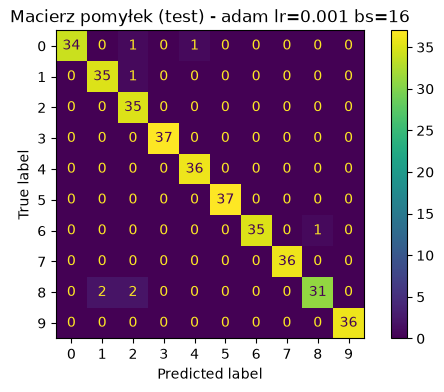

In [11]:
# TODO: wybierz model na podstawie walidacji.
# TODO: oblicz accuracy na teście i narysuj macierz pomyłek.

# Kryterium: najwyższe końcowe val_acc, przy remisie niższa val_loss.
best = max(torch_results, key=lambda r: (r["val_acc"], -r["val_loss"]))
best_model = trained_models[best["name"]]
print_experiment_table(sorted(torch_results, key=lambda r: (-r["val_acc"], r["val_loss"])))
print("\nWybrany model:", best["name"])

best_model.eval()
with torch.no_grad():
    test_logits = best_model(torch.tensor(X_test, dtype=torch.float32))
y_test_pred = test_logits.argmax(dim=1).numpy()

print(f"Accuracy na teście: {accuracy_score(y_test, y_test_pred):.3f}\n")
print(classification_report(y_test, y_test_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.title(f"Macierz pomyłek (test) - {best['name']}")
plt.grid(False)
plt.show()